# Experimento Final Fase 1: Evaluación Cruzada sobre Test Original (Sin Perturbaciones)

## 1. Objetivo del Experimento
Tras entrenar el modelo `BaselineMLP128` con perturbaciones espaciales de OpenCV (*Data Augmentation*) y observar un rendimiento del **65,09%** sobre el conjunto de prueba perturbado, en este último notebook evaluamos esos mismos pesos (`baseline_mlp_128_img_modificate.pth`) frente a las **4.005 imágenes originales del *test set*** (sin rotaciones, traslaciones ni zoom).

El propósito es cuantificar el compromiso (*trade-off*) sufrido por la red densa: comprobar cuánta precisión recupera en condiciones estándar y cuánto rendimiento ha sacrificado respecto al modelo original (76,48%) al intentar generalizar variaciones geométricas.

In [2]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix

# 1. Configuración de dispositivo (CPU) y semilla para reproducibilidad
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
print(f"[SETUP] Dispositivo en uso: {device.type.upper()}")

# 2. Definición de la arquitectura exacta del modelo entrenado
class BaselineMLP128(nn.Module):
    def __init__(self):
        super(BaselineMLP128, self).__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Linear(128 * 128 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.classifier(x)

# 3. Carga de los pesos entrenados con Data Augmentation
WEIGHTS_FILE = "baseline_mlp_128_img_modificate.pth"

model = BaselineMLP128().to(device)
model.load_state_dict(torch.load(WEIGHTS_FILE, map_location=device))
model.eval()

print(f"[OK] Pesos cargados correctamente desde '{WEIGHTS_FILE}'.")

[SETUP] Dispositivo en uso: CPU
[OK] Pesos cargados correctamente desde 'baseline_mlp_128_img_modificate.pth'.


## 2. Carga del Conjunto de Prueba Original (Limpio)
Preparamos el `DataLoader` aplicando únicamente el redimensionamiento estándar a $128 \times 128$ píxeles y la normalización al rango $[-1, 1]$, omitiendo por completo cualquier transformación geométrica de OpenCV.

In [4]:
# Transformación limpia (sin perturbaciones espaciales)
transform_test_limpio = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

DATASET_PATH = "./fase_2/secondo_archiviio/sample_10k/" 
test_dataset = datasets.ImageFolder(root=os.path.join(DATASET_PATH, "test"), transform=transform_test_limpio)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

print(f"[DATOS] Muestras de test originales cargadas: {len(test_dataset)} | Clases: {test_dataset.class_to_idx}")

[DATOS] Muestras de test originales cargadas: 4005 | Clases: {'fake': 0, 'real': 1}


## 3. Inferencia, Métricas y Matriz de Confusión
Ejecutamos la evaluación sin cálculo de gradientes (`torch.no_grad()`) para medir la latencia, extraer el informe de clasificación y analizar la distribución de aciertos y errores sobre las imágenes alineadas.

[TEST] Evaluando modelo aumentado sobre las imágenes de test originales...

[EFICIENCIA] Latencia media de inferencia: 0.2682 ms/imagen

[MÉTRICAS] Informe de Clasificación (Modelo Aumentado -> Test Limpio):
              precision    recall  f1-score   support

        fake     0.6322    0.8560    0.7273      2000
        real     0.7779    0.5032    0.6111      2005

    accuracy                         0.6794      4005
   macro avg     0.7051    0.6796    0.6692      4005
weighted avg     0.7052    0.6794    0.6691      4005



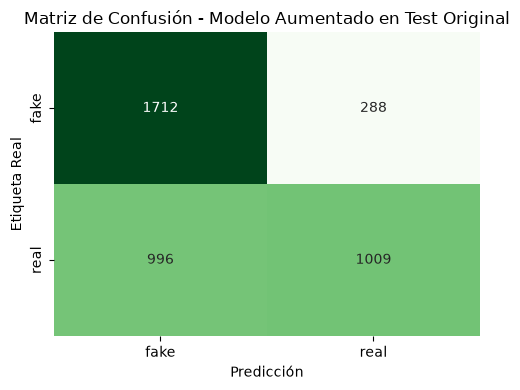

In [5]:
model.eval()
all_preds = []
all_labels = []
inference_times = []

print("[TEST] Evaluando modelo aumentado sobre las imágenes de test originales...")

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        
        t0 = time.perf_counter()
        outputs = model(images)
        t1 = time.perf_counter()
        
        inference_times.append((t1 - t0) / images.size(0))
        
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 1. Latencia media
avg_latency_ms = np.mean(inference_times) * 1000
print(f"\n[EFICIENCIA] Latencia media de inferencia: {avg_latency_ms:.4f} ms/imagen")

# 2. Informe de clasificación
class_names = list(test_dataset.class_to_idx.keys())
print("\n[MÉTRICAS] Informe de Clasificación (Modelo Aumentado -> Test Limpio):")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# 3. Matriz de Confusión
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta Real")
plt.title("Matriz de Confusión - Modelo Aumentado en Test Original")
plt.tight_layout()
plt.show()

## 4. Resumen Comparativo Global de la Fase 1 (Dataset 128x128)

Con este último experimento completamos la matriz de validación del modelo *Baseline* (`BaselineMLP128`):

| Configuración Experimental | Conjunto Train | Conjunto Test | Accuracy | Conclusión Técnica |
| :--- | :---: | :---: | :---: | :--- |
| **1. Baseline Estándar** | Original | Original | **76,48%** | Aprende coordenadas estáticas y estadísticas globales. |
| **2. Stress Test Espacial** | Original | Perturbado | **59,65%** | Colapso por falta de invarianza a la traslación/rotación. |
| **3. Data Augmentation (A)** | Perturbado | Perturbado | **65,09%** | Recuperación parcial; capacidad insuficiente para variar geometrías. |
| **4. Data Augmentation (B)** | Perturbado | Original | **67,94%** | Dilución de pesos: pierde precisión en imágenes alineadas (`Recall Real = 50,32%`) por exceso de falsos positivos. |

**Cierre de la Fase 1:** Queda demostrado experimentalmente que una arquitectura densa (MLP) no es adecuada para la detección robusta de imágenes sintéticas, estableciendo la necesidad de avanzar hacia el **Método 2 (HOG + LBP + SVM)** y el **Método 3 (CNN)** para capturar patrones espaciales locales invariantes a la posición.